# Machine Learning for Sound and Music 2026
## Lab 1: Music Genre Classification
##### Author: Lidia Wiśniewska
-----
### Background
Automatic genre classification using machine learning techniques is pivotal in managing
and enriching large-scale text and music collections. In textual data, assigning genre
labels—such as promotional or legal—enhances information retrieval by enabling users
to filter documents based on their specific needs, thereby improving search relevance and
efficiency. This automated labeling also aids in the curation of web corpora, ensuring a
diverse and representative dataset for training language models, which is essential for
advancing natural language processing applications. 

In the realm of music, genre classification facilitates the organization of extensive audio libraries, supporting
personalized recommendation systems and efficient content-based music retrieval. By
analyzing audio features, machine learning models can accurately categorize tracks into
genres like classical, jazz, or hip-hop, enhancing user experience in music streaming
services. Overall, the integration of automatic genre classification streamlines the
management of vast information repositories, making them more accessible and user-
centric

---
### Approach
This notebook implements genre classification using tradiitonal ML techniques:
* Logistic Regression
* kNN
* Decision Trees
* Random Forest
* ANN

---
### Structure
The notebook structure looks as follows: <br>
    1. [Data loading](#1-data-loading-and-eda)<br>
    2. [Feature engineering](#2-feature-engineering)<br>
    3. [Classification](#3-classification)<br>
    4. [Evaluation](#4-evaluation)<br>
    5. [Research questions]()<br>
    



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pylab as plt
from matplotlib.backends.backend_pdf import PdfPages
import seaborn as sns
plt.style.use('ggplot')
pd.set_option('display.max_columns', 250)

## 1. Data loading and EDA

In [2]:
genre_df = pd.read_csv("./data/GenreAll.csv", sep=",")
genre_df.columns = genre_df.columns.str.strip() #erase the whitespaces
feature_colnames = genre_df.columns.drop('genre').tolist()

print(f"Shape: {genre_df.shape[0]} rows, {genre_df.shape[1]} columns\n")
genre_df.head(10)

Shape: 993 rows, 241 columns



,highlevel_danceability_value,highlevel_equalization_profile_value,highlevel_excitement_value,highlevel_intensity_value,highlevel_speech_music_value,highlevel_voice_instrumental_value,loudness_dynamic_complexity_dvar,loudness_dynamic_complexity_mean,loudness_dynamic_complexity_var,loudness_larm_dvar,loudness_larm_mean,loudness_larm_var,loudness_replay_gain_value,loudness_vicker_dvar,loudness_vicker_mean,loudness_vicker_var,rhythm_beats_loudness_bass_dvar,rhythm_beats_loudness_bass_mean,rhythm_beats_loudness_bass_var,rhythm_beats_loudness_dvar,rhythm_beats_loudness_mean,rhythm_beats_loudness_var,rhythm_onset_rate_value,spectral_barkbands_00_dvar,spectral_barkbands_00_mean,spectral_barkbands_00_var,spectral_barkbands_01_dvar,spectral_barkbands_01_mean,spectral_barkbands_01_var,spectral_barkbands_02_dvar,spectral_barkbands_02_mean,spectral_barkbands_02_var,spectral_barkbands_03_dvar,spectral_barkbands_03_mean,spectral_barkbands_03_var,spectral_barkbands_04_dvar,spectral_barkbands_04_mean,spectral_barkbands_04_var,spectral_barkbands_05_dvar,spectral_barkbands_05_mean,spectral_barkbands_05_var,spectral_barkbands_06_dvar,spectral_barkbands_06_mean,spectral_barkbands_06_var,spectral_barkbands_07_dvar,spectral_barkbands_07_mean,spectral_barkbands_07_var,spectral_barkbands_08_dvar,spectral_barkbands_08_mean,spectral_barkbands_08_var,spectral_barkbands_09_dvar,spectral_barkbands_09_mean,spectral_barkbands_09_var,spectral_barkbands_10_dvar,spectral_barkbands_10_mean,spectral_barkbands_10_var,spectral_barkbands_11_dvar,spectral_barkbands_11_mean,spectral_barkbands_11_var,spectral_barkbands_12_dvar,spectral_barkbands_12_mean,spectral_barkbands_12_var,spectral_barkbands_13_dvar,spectral_barkbands_13_mean,spectral_barkbands_13_var,spectral_barkbands_14_dvar,spectral_barkbands_14_mean,spectral_barkbands_14_var,spectral_barkbands_15_dvar,spectral_barkbands_15_mean,spectral_barkbands_15_var,spectral_barkbands_16_dvar,spectral_barkbands_16_mean,spectral_barkbands_16_var,spectral_barkbands_17_dvar,spectral_barkbands_17_mean,spectral_barkbands_17_var,spectral_barkbands_18_dvar,spectral_barkbands_18_mean,spectral_barkbands_18_var,spectral_barkbands_19_dvar,spectral_barkbands_19_mean,spectral_barkbands_19_var,spectral_barkbands_20_dvar,spectral_barkbands_20_mean,spectral_barkbands_20_var,spectral_barkbands_21_dvar,spectral_barkbands_21_mean,spectral_barkbands_21_var,spectral_barkbands_22_dvar,spectral_barkbands_22_mean,spectral_barkbands_22_var,spectral_barkbands_23_dvar,spectral_barkbands_23_mean,spectral_barkbands_23_var,spectral_barkbands_24_dvar,spectral_barkbands_24_mean,spectral_barkbands_24_var,spectral_barkbands_25_dvar,spectral_barkbands_25_mean,spectral_barkbands_25_var,spectral_barkbands_kurtosis_dvar,spectral_barkbands_kurtosis_mean,spectral_barkbands_kurtosis_var,spectral_barkbands_skewness_dvar,spectral_barkbands_skewness_mean,spectral_barkbands_skewness_var,spectral_barkbands_spread_dvar,spectral_barkbands_spread_mean,spectral_barkbands_spread_var,spectral_centroid_dvar,spectral_centroid_mean,spectral_centroid_var,spectral_crest_dvar,spectral_crest_mean,spectral_crest_var,spectral_decrease_dvar,spectral_decrease_mean,spectral_decrease_var,spectral_energy_dvar,spectral_energy_mean,spectral_energy_var,spectral_energybandratio_high_dvar,spectral_energybandratio_high_mean,spectral_energybandratio_high_var,spectral_energybandratio_low_dvar,spectral_energybandratio_low_mean,spectral_energybandratio_low_var,spectral_energybandratio_middle_high_dvar,spectral_energybandratio_middle_high_mean,spectral_energybandratio_middle_high_var,spectral_energybandratio_middle_low_dvar,spectral_energybandratio_middle_low_mean,spectral_energybandratio_middle_low_var,spectral_flatness_db_dvar,spectral_flatness_db_mean,spectral_flatness_db_var,spectral_flux_dvar,spectral_flux_mean,spectral_flux_var,spectral_hfc_dvar,spectral_hfc_mean,spectral_hfc_var,spectral_kurtosis_dvar,spectral_kurtosis_mean,spectral_kurtosis_var,spectral_mfcc_00_dvar,spectral_mfcc_00_mean

#### Missing values and duplicates

In [3]:
missing_counts = genre_df.isna().sum()
missing_counts = missing_counts[missing_counts > 0]

print("Missing values by column:")
if missing_counts.empty:
    print("No missing values found.")
else:
    print(missing_counts.to_string())

Missing values by column:
No missing values found.


In [4]:
#check the duplicates only of feature columns to inspect possible mislabeling
duplicate_rows = genre_df[genre_df.duplicated(subset=feature_colnames, keep=False)] #keeping all versions to inspect

print(f"\nDuplicate rows found: {len(duplicate_rows)}")
duplicate_rows.sort_values(by=feature_colnames[:5])


Duplicate rows found: 28


,highlevel_danceability_value,highlevel_equalization_profile_value,highlevel_excitement_value,highlevel_intensity_value,highlevel_speech_music_value,highlevel_voice_instrumental_value,loudness_dynamic_complexity_dvar,loudness_dynamic_complexity_mean,loudness_dynamic_complexity_var,loudness_larm_dvar,loudness_larm_mean,loudness_larm_var,loudness_replay_gain_value,loudness_vicker_dvar,loudness_vicker_mean,loudness_vicker_var,rhythm_beats_loudness_bass_dvar,rhythm_beats_loudness_bass_mean,rhythm_beats_loudness_bass_var,rhythm_beats_loudness_dvar,rhythm_beats_loudness_mean,rhythm_beats_loudness_var,rhythm_onset_rate_value,spectral_barkbands_00_dvar,spectral_barkbands_00_mean,spectral_barkbands_00_var,spectral_barkbands_01_dvar,spectral_barkbands_01_mean,spectral_barkbands_01_var,spectral_barkbands_02_dvar,spectral_barkbands_02_mean,spectral_barkbands_02_var,spectral_barkbands_03_dvar,spectral_barkbands_03_mean,spectral_barkbands_03_var,spectral_barkbands_04_dvar,spectral_barkbands_04_mean,spectral_barkbands_04_var,spectral_barkbands_05_dvar,spectral_barkbands_05_mean,spectral_barkbands_05_var,spectral_barkbands_06_dvar,spectral_barkbands_06_mean,spectral_barkbands_06_var,spectral_barkbands_07_dvar,spectral_barkbands_07_mean,spectral_barkbands_07_var,spectral_barkbands_08_dvar,spectral_barkbands_08_mean,spectral_barkbands_08_var,spectral_barkbands_09_dvar,spectral_barkbands_09_mean,spectral_barkbands_09_var,spectral_barkbands_10_dvar,spectral_barkbands_10_mean,spectral_barkbands_10_var,spectral_barkbands_11_dvar,spectral_barkbands_11_mean,spectral_barkbands_11_var,spectral_barkbands_12_dvar,spectral_barkbands_12_mean,spectral_barkbands_12_var,spectral_barkbands_13_dvar,spectral_barkbands_13_mean,spectral_barkbands_13_var,spectral_barkbands_14_dvar,spectral_barkbands_14_mean,spectral_barkbands_14_var,spectral_barkbands_15_dvar,spectral_barkbands_15_mean,spectral_barkbands_15_var,spectral_barkbands_16_dvar,spectral_barkbands_16_mean,spectral_barkbands_16_var,spectral_barkbands_17_dvar,spectral_barkbands_17_mean,spectral_barkbands_17_var,spectral_barkbands_18_dvar,spectral_barkbands_18_mean,spectral_barkbands_18_var,spectral_barkbands_19_dvar,spectral_barkbands_19_mean,spectral_barkbands_19_var,spectral_barkbands_20_dvar,spectral_barkbands_20_mean,spectral_barkbands_20_var,spectral_barkbands_21_dvar,spectral_barkbands_21_mean,spectral_barkbands_21_var,spectral_barkbands_22_dvar,spectral_barkbands_22_mean,spectral_barkbands_22_var,spectral_barkbands_23_dvar,spectral_barkbands_23_mean,spectral_barkbands_23_var,spectral_barkbands_24_dvar,spectral_barkbands_24_mean,spectral_barkbands_24_var,spectral_barkbands_25_dvar,spectral_barkbands_25_mean,spectral_barkbands_25_var,spectral_barkbands_kurtosis_dvar,spectral_barkbands_kurtosis_mean,spectral_barkbands_kurtosis_var,spectral_barkbands_skewness_dvar,spectral_barkbands_skewness_mean,spectral_barkbands_skewness_var,spectral_barkbands_spread_dvar,spectral_barkbands_spread_mean,spectral_barkbands_spread_var,spectral_centroid_dvar,spectral_centroid_mean,spectral_centroid_var,spectral_crest_dvar,spectral_crest_mean,spectral_crest_var,spectral_decrease_dvar,spectral_decrease_mean,spectral_decrease_var,spectral_energy_dvar,spectral_energy_mean,spectral_energy_var,spectral_energybandratio_high_dvar,spectral_energybandratio_high_mean,spectral_energybandratio_high_var,spectral_energybandratio_low_dvar,spectral_energybandratio_low_mean,spectral_energybandratio_low_var,spectral_energybandratio_middle_high_dvar,spectral_energybandratio_middle_high_mean,spectral_energybandratio_middle_high_var,spectral_energybandratio_middle_low_dvar,spectral_energybandratio_middle_low_mean,spectral_energybandratio_middle_low_var,spectral_flatness_db_dvar,spectral_flatness_db_mean,spectral_flatness_db_var,spectral_flux_dvar,spectral_flux_mean,spectral_flux_var,spectral_hfc_dvar,spectral_hfc_mean,spectral_hfc_var,spectral_kurtosis_dvar,spectral_kurtosis_mean,spectral_kurtosis_var,spectral_mfcc_00_dvar,spectral_mfcc_00_mean

We have 14 pairs of duplicates, in which 1 pair is mislabeled (the same sample has 2 different genres). As we can't listen to the samples, the safest is to discard both entries, while for the rest of the 13 pairs to keep the first occurence.

In [5]:
genre_counts = genre_df.groupby(feature_colnames)['genre'].transform('nunique')
safe_df = genre_df[genre_counts == 1]
genre_df = safe_df.drop_duplicates(subset=feature_colnames, keep='first').reset_index(drop=True)

print(f"Shape: {genre_df.shape[0]} rows, {genre_df.shape[1]} columns\n")
genre_df.head(5)

Shape: 978 rows, 241 columns



,highlevel_danceability_value,highlevel_equalization_profile_value,highlevel_excitement_value,highlevel_intensity_value,highlevel_speech_music_value,highlevel_voice_instrumental_value,loudness_dynamic_complexity_dvar,loudness_dynamic_complexity_mean,loudness_dynamic_complexity_var,loudness_larm_dvar,loudness_larm_mean,loudness_larm_var,loudness_replay_gain_value,loudness_vicker_dvar,loudness_vicker_mean,loudness_vicker_var,rhythm_beats_loudness_bass_dvar,rhythm_beats_loudness_bass_mean,rhythm_beats_loudness_bass_var,rhythm_beats_loudness_dvar,rhythm_beats_loudness_mean,rhythm_beats_loudness_var,rhythm_onset_rate_value,spectral_barkbands_00_dvar,spectral_barkbands_00_mean,spectral_barkbands_00_var,spectral_barkbands_01_dvar,spectral_barkbands_01_mean,spectral_barkbands_01_var,spectral_barkbands_02_dvar,spectral_barkbands_02_mean,spectral_barkbands_02_var,spectral_barkbands_03_dvar,spectral_barkbands_03_mean,spectral_barkbands_03_var,spectral_barkbands_04_dvar,spectral_barkbands_04_mean,spectral_barkbands_04_var,spectral_barkbands_05_dvar,spectral_barkbands_05_mean,spectral_barkbands_05_var,spectral_barkbands_06_dvar,spectral_barkbands_06_mean,spectral_barkbands_06_var,spectral_barkbands_07_dvar,spectral_barkbands_07_mean,spectral_barkbands_07_var,spectral_barkbands_08_dvar,spectral_barkbands_08_mean,spectral_barkbands_08_var,spectral_barkbands_09_dvar,spectral_barkbands_09_mean,spectral_barkbands_09_var,spectral_barkbands_10_dvar,spectral_barkbands_10_mean,spectral_barkbands_10_var,spectral_barkbands_11_dvar,spectral_barkbands_11_mean,spectral_barkbands_11_var,spectral_barkbands_12_dvar,spectral_barkbands_12_mean,spectral_barkbands_12_var,spectral_barkbands_13_dvar,spectral_barkbands_13_mean,spectral_barkbands_13_var,spectral_barkbands_14_dvar,spectral_barkbands_14_mean,spectral_barkbands_14_var,spectral_barkbands_15_dvar,spectral_barkbands_15_mean,spectral_barkbands_15_var,spectral_barkbands_16_dvar,spectral_barkbands_16_mean,spectral_barkbands_16_var,spectral_barkbands_17_dvar,spectral_barkbands_17_mean,spectral_barkbands_17_var,spectral_barkbands_18_dvar,spectral_barkbands_18_mean,spectral_barkbands_18_var,spectral_barkbands_19_dvar,spectral_barkbands_19_mean,spectral_barkbands_19_var,spectral_barkbands_20_dvar,spectral_barkbands_20_mean,spectral_barkbands_20_var,spectral_barkbands_21_dvar,spectral_barkbands_21_mean,spectral_barkbands_21_var,spectral_barkbands_22_dvar,spectral_barkbands_22_mean,spectral_barkbands_22_var,spectral_barkbands_23_dvar,spectral_barkbands_23_mean,spectral_barkbands_23_var,spectral_barkbands_24_dvar,spectral_barkbands_24_mean,spectral_barkbands_24_var,spectral_barkbands_25_dvar,spectral_barkbands_25_mean,spectral_barkbands_25_var,spectral_barkbands_kurtosis_dvar,spectral_barkbands_kurtosis_mean,spectral_barkbands_kurtosis_var,spectral_barkbands_skewness_dvar,spectral_barkbands_skewness_mean,spectral_barkbands_skewness_var,spectral_barkbands_spread_dvar,spectral_barkbands_spread_mean,spectral_barkbands_spread_var,spectral_centroid_dvar,spectral_centroid_mean,spectral_centroid_var,spectral_crest_dvar,spectral_crest_mean,spectral_crest_var,spectral_decrease_dvar,spectral_decrease_mean,spectral_decrease_var,spectral_energy_dvar,spectral_energy_mean,spectral_energy_var,spectral_energybandratio_high_dvar,spectral_energybandratio_high_mean,spectral_energybandratio_high_var,spectral_energybandratio_low_dvar,spectral_energybandratio_low_mean,spectral_energybandratio_low_var,spectral_energybandratio_middle_high_dvar,spectral_energybandratio_middle_high_mean,spectral_energybandratio_middle_high_var,spectral_energybandratio_middle_low_dvar,spectral_energybandratio_middle_low_mean,spectral_energybandratio_middle_low_var,spectral_flatness_db_dvar,spectral_flatness_db_mean,spectral_flatness_db_var,spectral_flux_dvar,spectral_flux_mean,spectral_flux_var,spectral_hfc_dvar,spectral_hfc_mean,spectral_hfc_var,spectral_kurtosis_dvar,spectral_kurtosis_mean,spectral_kurtosis_var,spectral_mfcc_00_dvar,spectral_mfcc_00_mean

#### Datatypes

In [6]:
print(f"Unique data types: {genre_df.dtypes.unique().tolist()}")
print("\nAll column data types:\n")
genre_df.dtypes

Unique data types: [dtype('float64'), <StringDtype(storage='python', na_value=nan)>, dtype('int64')]

All column data types:



highlevel_danceability_value                   float64
highlevel_equalization_profile_value           float64
highlevel_excitement_value                     float64
highlevel_intensity_value                      float64
highlevel_speech_music_value                       str
                                                ...   
tonal_dissonance_var                           float64
tonal_key_mode_value                               str
tonal_key_strength_value                       float64
tonal_tuning_equal_tempered_deviation_value    float64
genre                                              str
Length: 241, dtype: object

As we can see we have mostly numeric (float) data with ocasional strings and integers.

In [7]:
cat_columns = genre_df.select_dtypes(include='string').columns
num_columns = genre_df.select_dtypes(include="number").columns

assert len(num_columns)+len(cat_columns)==genre_df.shape[1], "You just lost some columns..."

#### Numerical columns

In [8]:
feature_df_descr = genre_df[num_columns].describe()
feature_df_descr

,highlevel_danceability_value,highlevel_equalization_profile_value,highlevel_excitement_value,highlevel_intensity_value,loudness_dynamic_complexity_dvar,loudness_dynamic_complexity_mean,loudness_dynamic_complexity_var,loudness_larm_dvar,loudness_larm_mean,loudness_larm_var,loudness_replay_gain_value,loudness_vicker_dvar,loudness_vicker_mean,loudness_vicker_var,rhythm_beats_loudness_bass_dvar,rhythm_beats_loudness_bass_mean,rhythm_beats_loudness_bass_var,rhythm_beats_loudness_dvar,rhythm_beats_loudness_mean,rhythm_beats_loudness_var,rhythm_onset_rate_value,spectral_barkbands_00_dvar,spectral_barkbands_00_mean,spectral_barkbands_00_var,spectral_barkbands_01_dvar,spectral_barkbands_01_mean,spectral_barkbands_01_var,spectral_barkbands_02_dvar,spectral_barkbands_02_mean,spectral_barkbands_02_var,spectral_barkbands_03_dvar,spectral_barkbands_03_mean,spectral_barkbands_03_var,spectral_barkbands_04_dvar,spectral_barkbands_04_mean,spectral_barkbands_04_var,spectral_barkbands_05_dvar,spectral_barkbands_05_mean,spectral_barkbands_05_var,spectral_barkbands_06_dvar,spectral_barkbands_06_mean,spectral_barkbands_06_var,spectral_barkbands_07_dvar,spectral_barkbands_07_mean,spectral_barkbands_07_var,spectral_barkbands_08_dvar,spectral_barkbands_08_mean,spectral_barkbands_08_var,spectral_barkbands_09_dvar,spectral_barkbands_09_mean,spectral_barkbands_09_var,spectral_barkbands_10_dvar,spectral_barkbands_10_mean,spectral_barkbands_10_var,spectral_barkbands_11_dvar,spectral_barkbands_11_mean,spectral_barkbands_11_var,spectral_barkbands_12_dvar,spectral_barkbands_12_mean,spectral_barkbands_12_var,spectral_barkbands_13_dvar,spectral_barkbands_13_mean,spectral_barkbands_13_var,spectral_barkbands_14_dvar,spectral_barkbands_14_mean,spectral_barkbands_14_var,spectral_barkbands_15_dvar,spectral_barkbands_15_mean,spectral_barkbands_15_var,spectral_barkbands_16_dvar,spectral_barkbands_16_mean,spectral_barkbands_16_var,spectral_barkbands_17_dvar,spectral_barkbands_17_mean,spectral_barkbands_17_var,spectral_barkbands_18_dvar,spectral_barkbands_18_mean,spectral_barkbands_18_var,spectral_barkbands_19_dvar,spectral_barkbands_19_mean,spectral_barkbands_19_var,spectral_barkbands_20_dvar,spectral_barkbands_20_mean,spectral_barkbands_20_var,spectral_barkbands_21_dvar,spectral_barkbands_21_mean,spectral_barkbands_21_var,spectral_barkbands_22_dvar,spectral_barkbands_22_mean,spectral_barkbands_22_var,spectral_barkbands_23_dvar,spectral_barkbands_23_mean,spectral_barkbands_23_var,spectral_barkbands_24_dvar,spectral_barkbands_24_mean,spectral_barkbands_24_var,spectral_barkbands_25_dvar,spectral_barkbands_25_mean,spectral_barkbands_25_var,spectral_barkbands_kurtosis_dvar,spectral_barkbands_kurtosis_mean,spectral_barkbands_kurtosis_var,spectral_barkbands_skewness_dvar,spectral_barkbands_skewness_mean,spectral_barkbands_skewness_var,spectral_barkbands_spread_dvar,spectral_barkbands_spread_mean,spectral_barkbands_spread_var,spectral_centroid_dvar,spectral_centroid_mean,spectral_centroid_var,spectral_crest_dvar,spectral_crest_mean,spectral_crest_var,spectral_decrease_dvar,spectral_decrease_mean,spectral_decrease_var,spectral_energy_dvar,spectral_energy_mean,spectral_energy_var,spectral_energybandratio_high_dvar,spectral_energybandratio_high_mean,spectral_energybandratio_high_var,spectral_energybandratio_low_dvar,spectral_energybandratio_low_mean,spectral_energybandratio_low_var,spectral_energybandratio_middle_high_dvar,spectral_energybandratio_middle_high_mean,spectral_energybandratio_middle_high_var,spectral_energybandratio_middle_low_dvar,spectral_energybandratio_middle_low_mean,spectral_energybandratio_middle_low_var,spectral_flatness_db_dvar,spectral_flatness_db_mean,spectral_flatness_db_var,spectral_flux_dvar,spectral_flux_mean,spectral_flux_var,spectral_hfc_dvar,spectral_hfc_mean,spectral_hfc_var,spectral_kurtosis_dvar,spectral_kurtosis_mean,spectral_kurtosis_var,spectral_mfcc_00_dvar,spectral_mfcc_00_mean,spectral_mfcc_00_var,spectral_mfcc_01_dvar,spectral_mfcc_01_mea

Most of the features are centered around 0 and have std close to 1, meaning they are standardized. However, the ranges differ and the features will require some normalization later on.

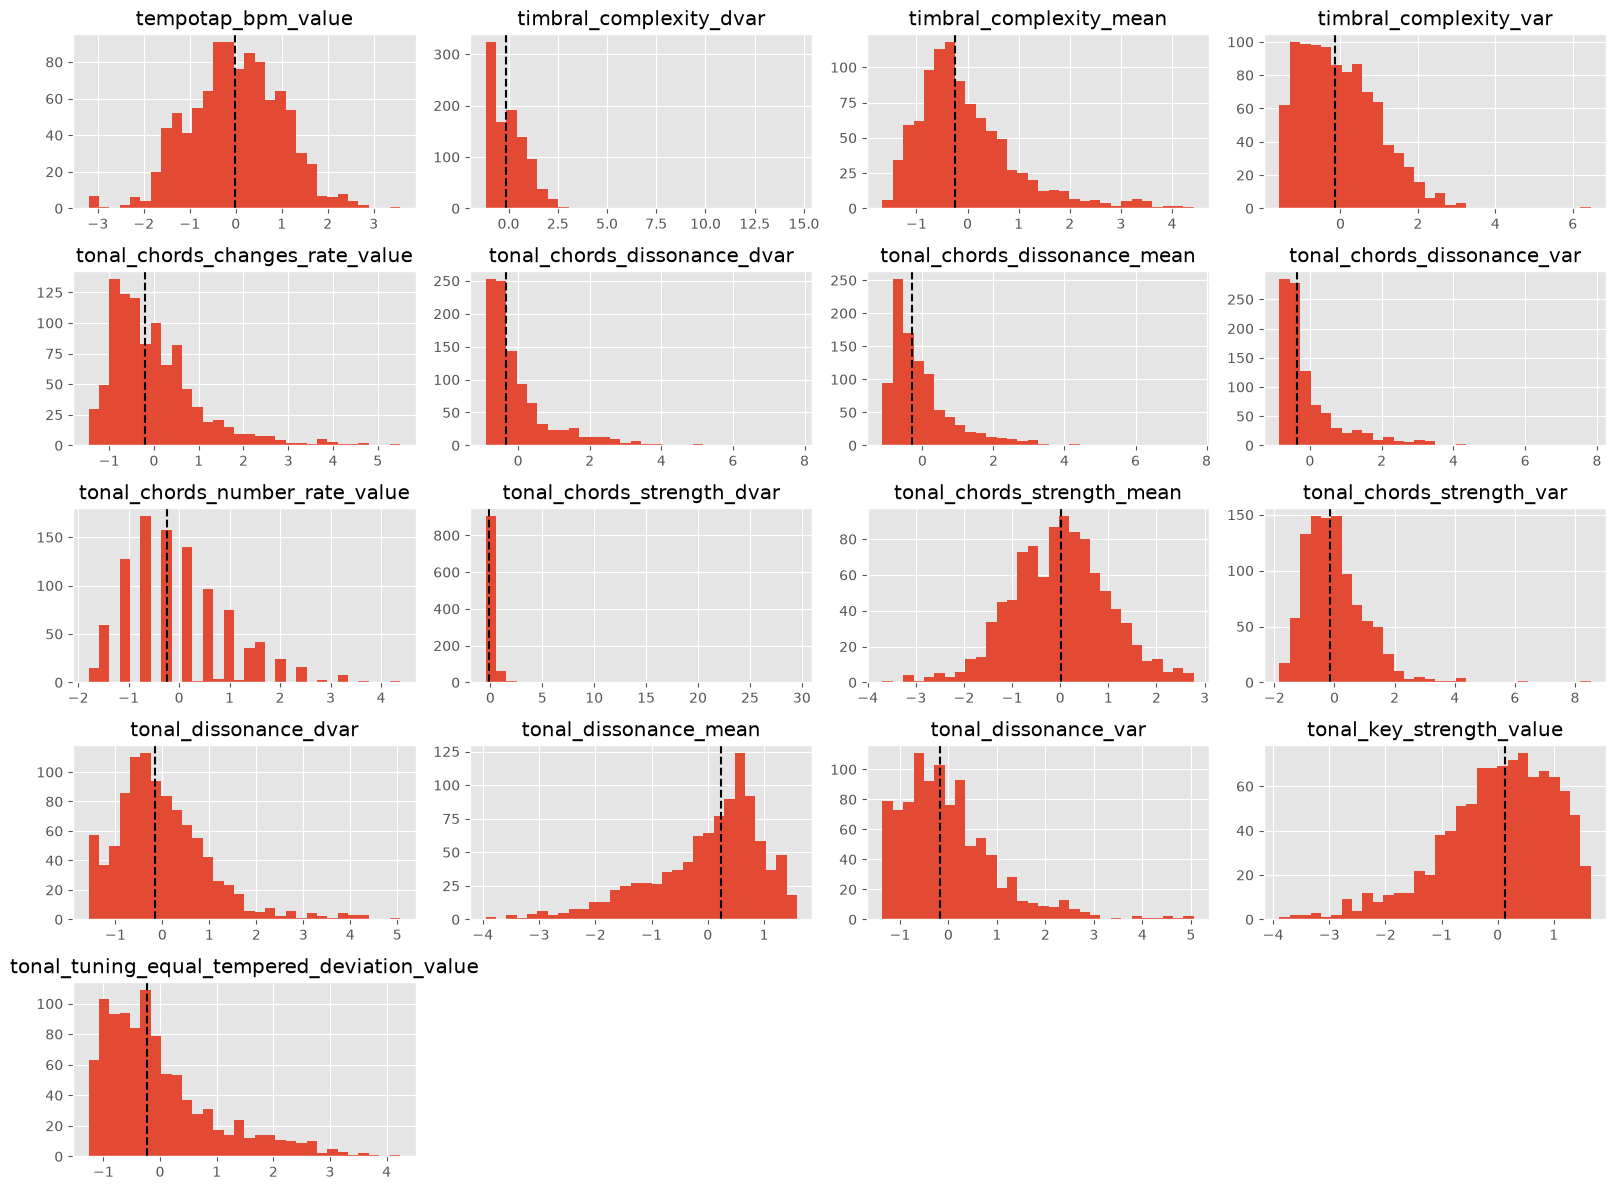

In [9]:
#distributions
with PdfPages("./data/task1_distributions.pdf") as pdf:
    for start in range(0, len(num_columns), 20):
        cols=num_columns[start:start+20]
        axes = genre_df[num_columns][cols].hist(bins=30, figsize=(16, 12))

        for ax, col in zip(axes.ravel(), cols):
            median = feature_df_descr.loc["50%", col]
            ax.axvline(median, color="black", linestyle="--", linewidth=1.5)
        fig = axes.ravel()[0].figure
        fig.tight_layout()
        pdf.savefig(fig)

        if start + 20 < len(num_columns):
            plt.close(fig)
        last_fig = fig

if last_fig is not None:
    plt.show()

The plots don't support the standardization of the data, however show that many columns represent different statistics of the same feature, e.g. for tonal_dissonance we have 3 columns: dvar, mean and var. Additionally we are working with many different distributions and skewness levels. Additionally, after inspecting the rest of the plots (saved in a file), we can observe that most of the `_var` and `_dvar` features are not really spread, meaning they are concentrated around 0 and do not go very far from that value.

In [9]:
#variance check
feature_df_descr.iloc[2, :].sort_values(ascending=True).head(5)


spectral_barkbands_25_var          0.000000
spectral_barkbands_25_dvar         0.000000
rhythm_beats_loudness_bass_dvar    0.978101
spectral_barkbands_16_mean         0.984197
spectral_strongpeak_var            0.985805
Name: std, dtype: float64

This shows that features `spectral_barkbands_25_var` and `spectral_barkbands_25_dvar` have std of 0, so are basically constant features and are redundant.

In [10]:
col_to_drop = feature_df_descr.iloc[2, :].sort_values(ascending=True).head(2).index.astype(str).tolist()
num_columns = num_columns.drop(col_to_drop)
genre_df.drop(col_to_drop, axis=1, inplace=True)
genre_df.shape

(978, 239)

In [11]:
#mean check
feature_df_descr.iloc[1, :].sort_values(ascending=False).head(5)
mean_max = feature_df_descr.iloc[1, :].max()
mean_min = feature_df_descr.iloc[1, :].min()
print(f"The highest mean value: {mean_max}, the lowest mean value: {mean_min}")


The highest mean value: 0.012395018404907957, the lowest mean value: -0.01760213803680981


In [12]:
#min check
feature_df_descr.iloc[3, :].sort_values(ascending=True).head(5)

loudness_vicker_mean    -5.653249
spectral_mfcc_11_mean   -4.842011
spectral_mfcc_10_mean   -4.774977
spectral_mfcc_09_mean   -4.772353
loudness_larm_mean      -4.734653
Name: min, dtype: float64

In [13]:
#max check
feature_df_descr.iloc[7, :].sort_values(ascending=False).head(10)

tonal_chords_strength_dvar         29.521946
spectral_mfcc_03_dvar              28.574514
spectral_barkbands_14_var          27.077678
spectral_barkbands_22_var          25.743854
loudness_larm_var                  25.411209
spectral_barkbands_06_var          25.137454
spectral_barkbands_00_dvar         24.500464
spectral_silence_rate_60dB_dvar    24.430404
spectral_barkbands_20_dvar         23.945951
spectral_barkbands_05_dvar         23.847306
Name: max, dtype: float64

We can observe that the minimal values start around -5 and the maximal values are up to even 29. At first glance they don't look like outliers.

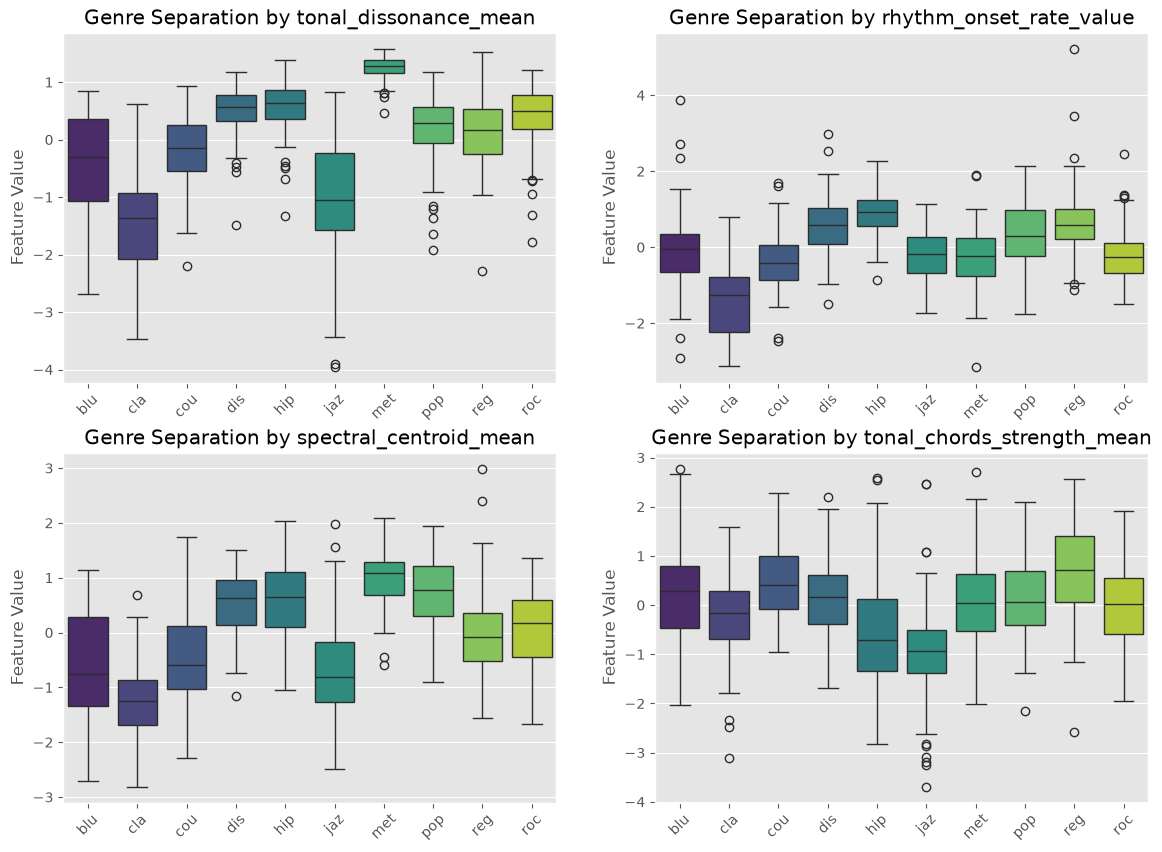

In [14]:
#primary target separation inspection

to_inspect = ["tonal_dissonance_mean",
              "rhythm_onset_rate_value",
              "spectral_centroid_mean",
              "tonal_chords_strength_mean",
              ]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, feature in enumerate(to_inspect):
    sns.boxplot(data=genre_df, x='genre', y=feature, ax=axes[i], hue="genre",legend=False, palette='viridis')
    axes[i].set_title(f'Genre Separation by {feature}')
    axes[i].set_ylabel('Feature Value')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=45)

plt.show()

By taking random features we can observe that complete target separation was not possible (which would be a miracle having randomly chosen the features and 10 distinct classes). Yet, noticeable is some grouping of families/separation based on characteristics a specific feature has measured.

Starting with `tonal_dissonance_mean` feature  we can observe that it heavily isolates metal at the extreme top, while grouping jazz and classical together at the very bottom. On the other hand, `rhythm_onset_rate_value` groups groove-centric genres like hip-hop, disco, and reggae high up the scale, putting classical completely separate at the lowest end. 

Looking at `spectral_centroid_mean`, it groups together classical, blues, jazz and country, while hiphop, metal and pop stand together. Finally, we can observe that `tonal_chords_strength_mean` clearly separates reggae by placing it at the top, while clustering hip-hop and jazz together in the negative values because their harmonies are too complex (jazz) or buried under the beat (hip-hop).

Additionally, we should notice the presence of outliers depending on the feature/category combination. This should be adressed in the future.
 


In [15]:
#heatmaps
def feature_family(name):
    if name.startswith("highlevel_"):
        return "highlevel"
    if name.startswith("loudness_"):
        return "loudness"
    if name.startswith(("rhythm_", "tempotap_")):
        return "rhythm"
    if name.startswith("spectral_"):
        return "spectral"
    if name.startswith("temporal_"):
        return "temporal"
    if name.startswith("timbral_"):
        return "timbral"
    if name.startswith("tonal_"):
        return "tonal"
    return "other"


family_order = [
    "highlevel", "loudness", "rhythm", "spectral",
    "temporal", "timbral", "tonal", "other",
]


def plot_family_heatmap(matrix, title, mask_upper=False):
    family_by_feature = {name: feature_family(name) for name in matrix.columns}
    ordered_features = sorted(
        matrix.columns,
        key=lambda name: (family_order.index(family_by_feature[name]), name),
    )
    ordered = matrix.loc[ordered_features, ordered_features]
    families = [family_by_feature[name] for name in ordered_features]
    n_features = len(ordered_features)

    fig, ax = plt.subplots(
        figsize=(max(16, n_features * 0.12), max(14, n_features * 0.12))
    )
    mask = np.triu(np.ones(ordered.shape, dtype=bool)) if mask_upper else None

    sns.heatmap(
        ordered,
        ax=ax,
        mask=mask,
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        xticklabels=True,
        yticklabels=True,
        cbar_kws={"shrink": 0.65},
    )

    group_positions = {}
    for position, family in enumerate(families):
        group_positions.setdefault(family, []).append(position)

    family_names = list(group_positions)
    family_centers = [
        np.mean(group_positions[family]) + 0.5 for family in family_names
    ]
    boundaries = [
        group_positions[family][-1] + 1 for family in family_names[:-1]
    ]

    for boundary in boundaries:
        ax.axhline(boundary, color="black", linewidth=1)
        ax.axvline(boundary, color="black", linewidth=1)

    top_ax = ax.twiny()
    top_ax.set_xlim(ax.get_xlim())
    top_ax.set_xticks(family_centers)
    top_ax.set_xticklabels(family_names, fontsize=8)
    top_ax.tick_params(axis="x", length=0, pad=4)
    top_ax.spines["top"].set_visible(False)

    right_ax = ax.twinx()
    right_ax.set_ylim(ax.get_ylim())
    right_ax.set_yticks(family_centers)
    right_ax.set_yticklabels(family_names, fontsize=8)
    right_ax.tick_params(axis="y", length=0, pad=4)
    right_ax.spines["right"].set_visible(False)

    feature_font = max(3, min(7, 600 / n_features))
    ax.tick_params(axis="x", labelrotation=90, labelsize=feature_font)
    ax.tick_params(axis="y", labelrotation=0, labelsize=feature_font)
    ax.set_title(title, pad=34)
    fig.subplots_adjust(top=0.92, right=0.88, bottom=0.2, left=0.23)
    plt.show()


Reduced heatmap from 235 to 64 highly correlated features.


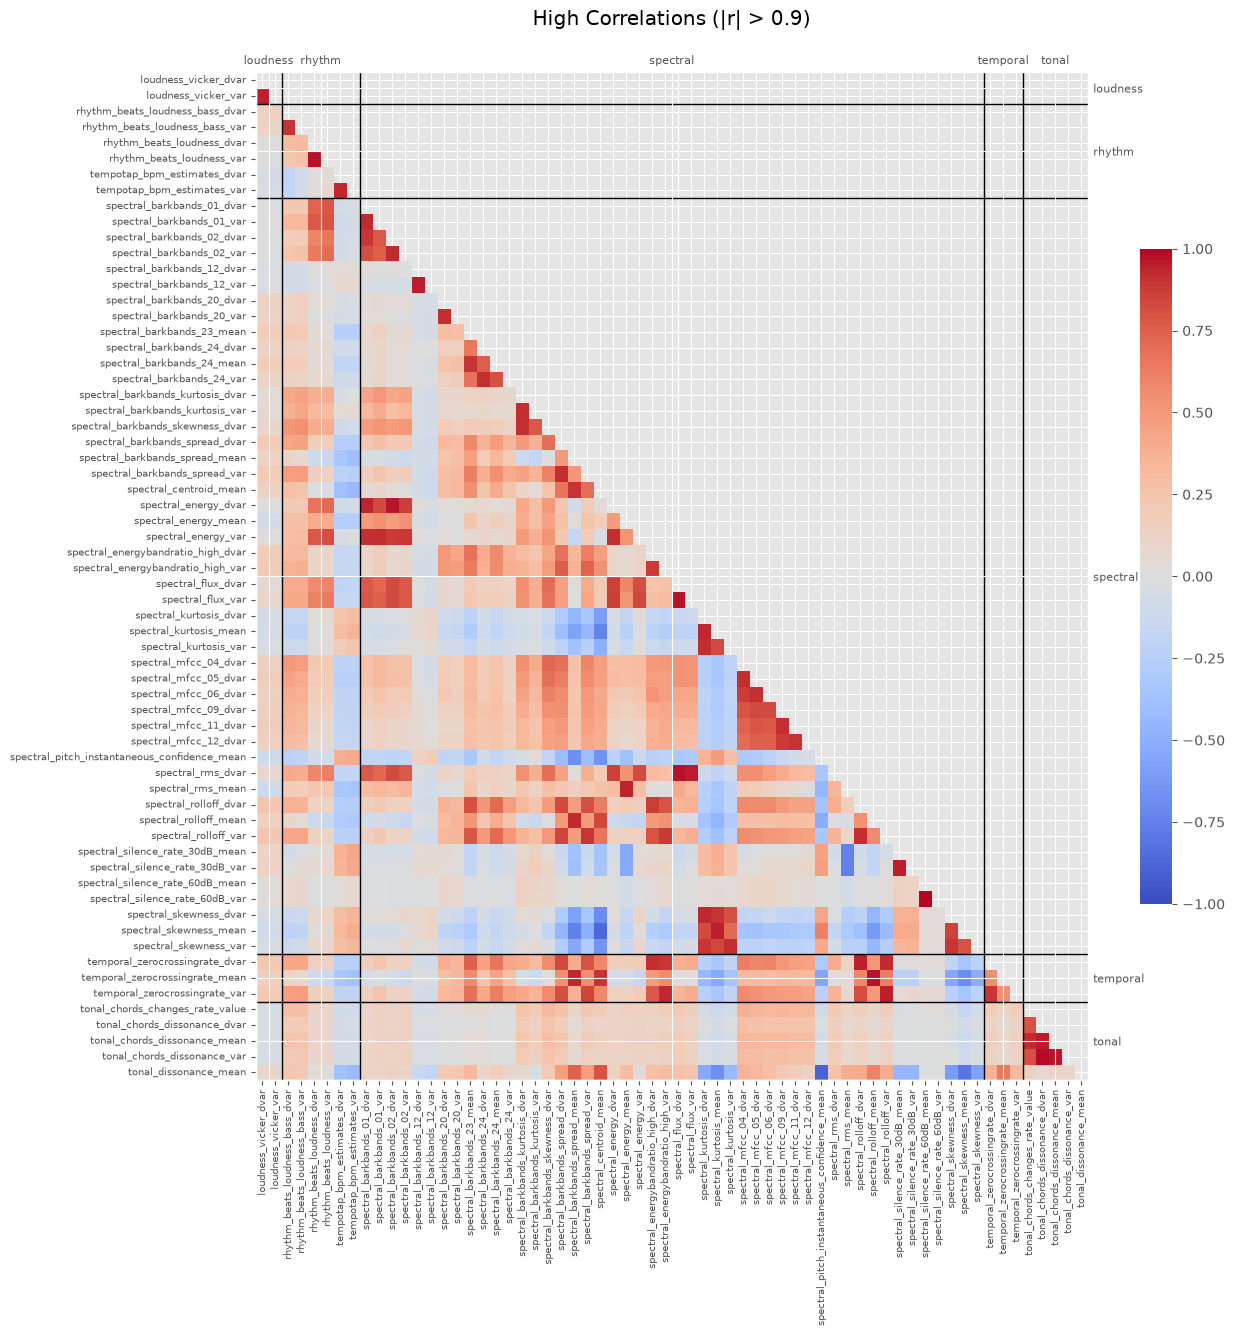

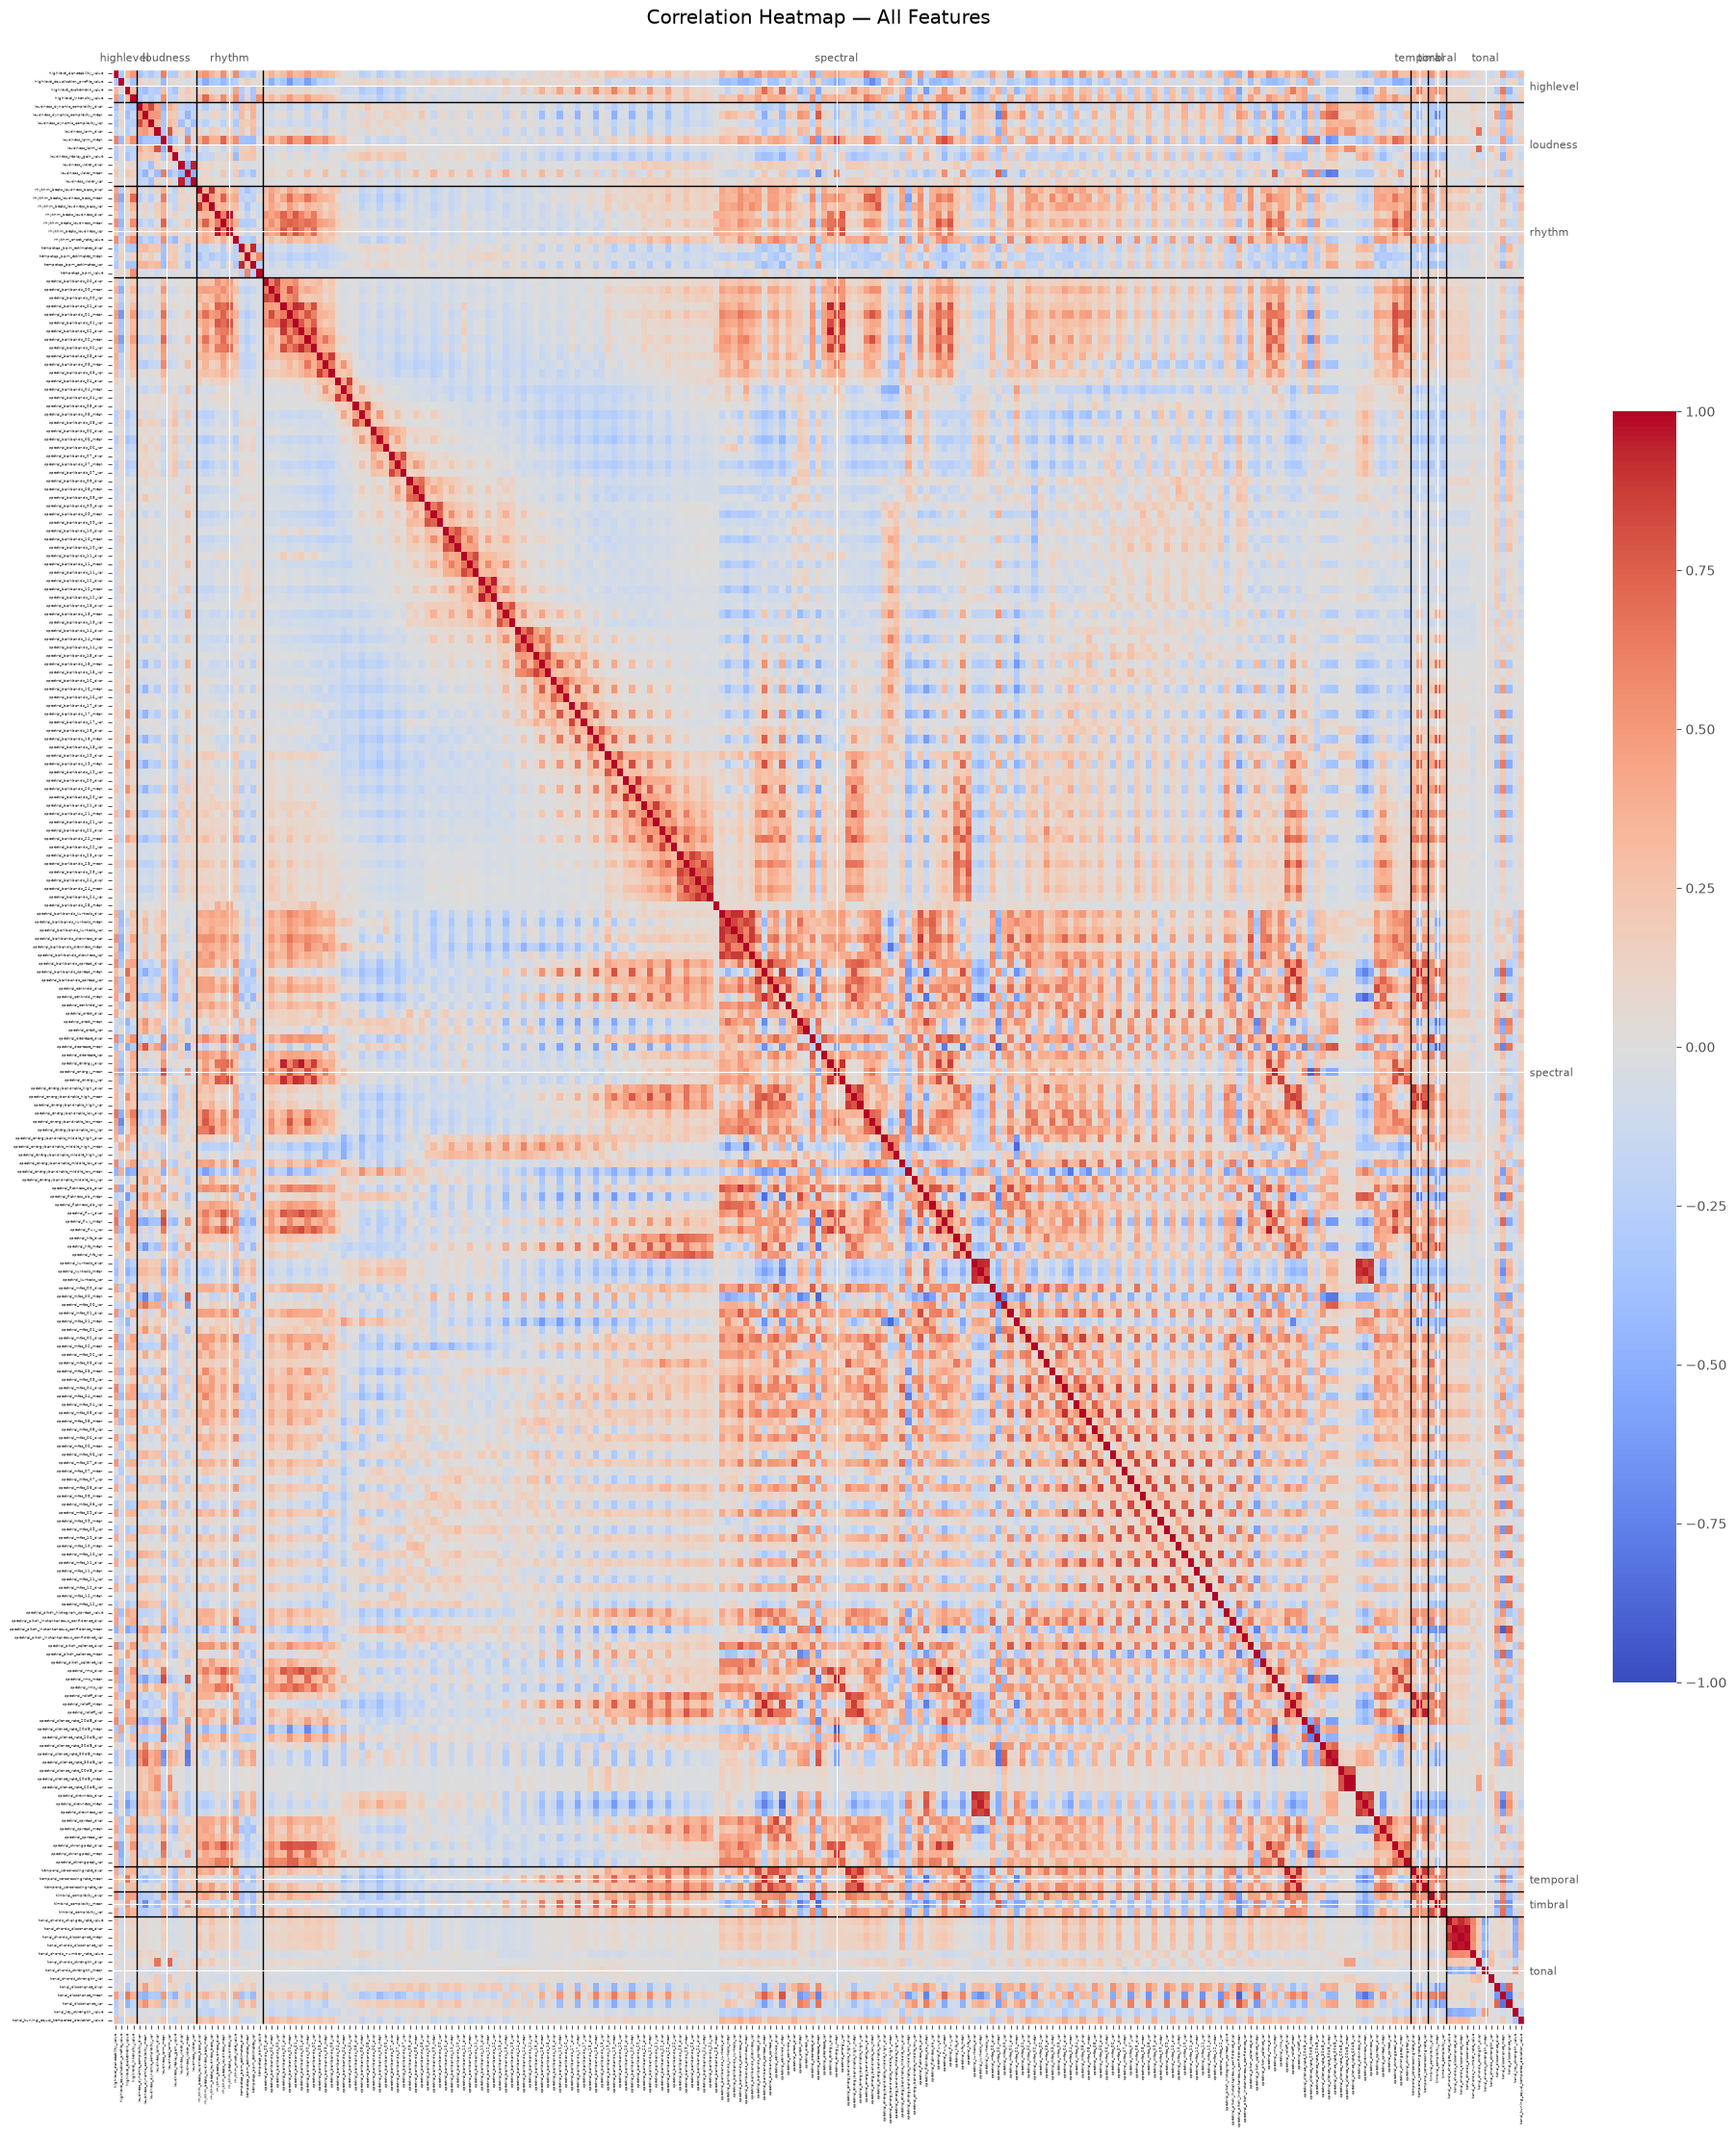

In [16]:
corr_matrix = genre_df[num_columns].corr()
threshold = 0.9

strong_correlations = corr_matrix.abs().where(
    ~np.eye(len(corr_matrix), dtype=bool)
).gt(threshold)
features_with_strong_correlations = strong_correlations.any(axis=0)
high_corr_matrix = corr_matrix.loc[
    features_with_strong_correlations,
    features_with_strong_correlations,
]

print(
    f"Reduced heatmap from {len(num_columns)} to "
    f"{len(high_corr_matrix.columns)} highly correlated features."
)

plot_family_heatmap(
    high_corr_matrix,
    f"High Correlations (|r| > {threshold})",
    mask_upper=True,
)

plot_family_heatmap(
    corr_matrix,
    "Correlation Heatmap — All Features",
)

#### Categorical columns

In [15]:
for c in cat_columns:
    print(f"Values in the column {c}: {genre_df[c].unique().tolist()}")
    
binary_cols_names = cat_columns[:3]
target_col_name = cat_columns[3]

Values in the column highlevel_speech_music_value: ['speech', 'music']
Values in the column highlevel_voice_instrumental_value: ['instrumental', 'voice']
Values in the column tonal_key_mode_value: ['major', 'minor']
Values in the column genre: ['blu', 'cla', 'cou', 'dis', 'hip', 'jaz', 'met', 'pop', 'reg', 'roc']


We observe that the target column has 10 classes, while each of the independent columns has only two values, so later we can use 0/1 encoding to transform those features into numerical columns.

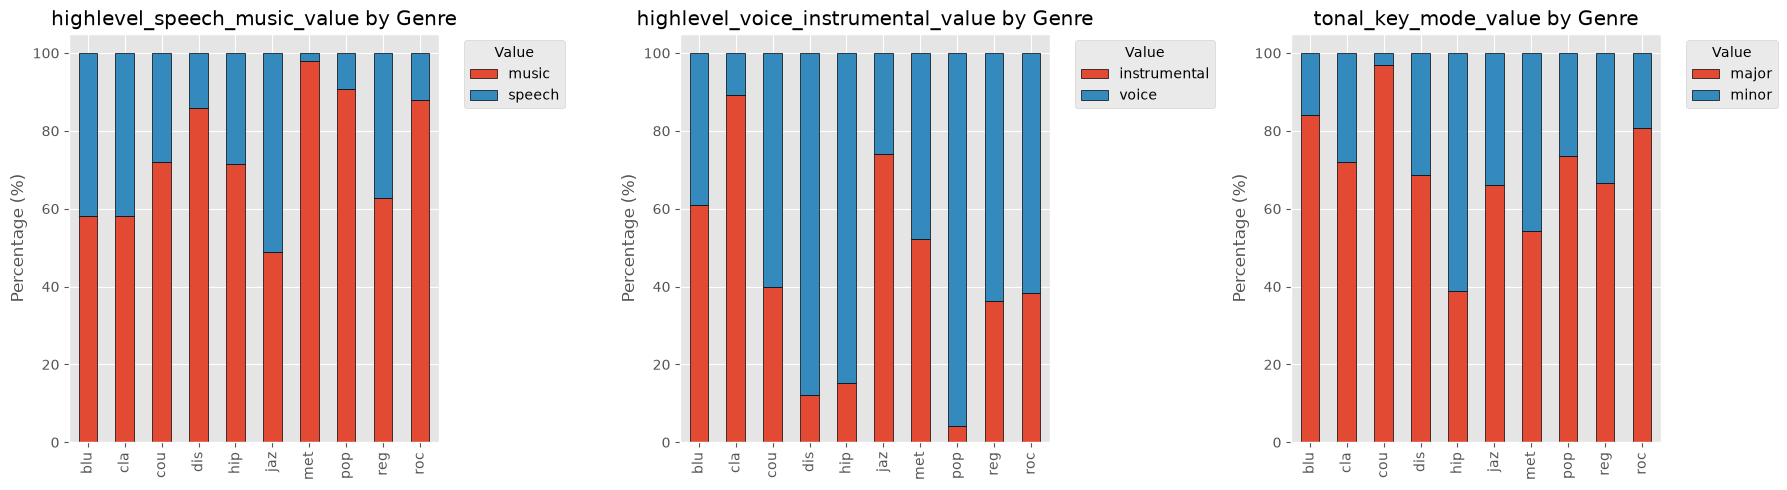

In [16]:
#cross-tabulation
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(binary_cols_names):
    crosstab = pd.crosstab(genre_df[target_col_name], genre_df[col], normalize='index')*100
    crosstab.plot(kind='bar', stacked=True, ax=axes[i], edgecolor='black')

    axes[i].set_title(f'{col} by Genre')
    axes[i].set_ylabel('Percentage (%)')
    axes[i].set_xlabel('')
    axes[i].legend(title='Value', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

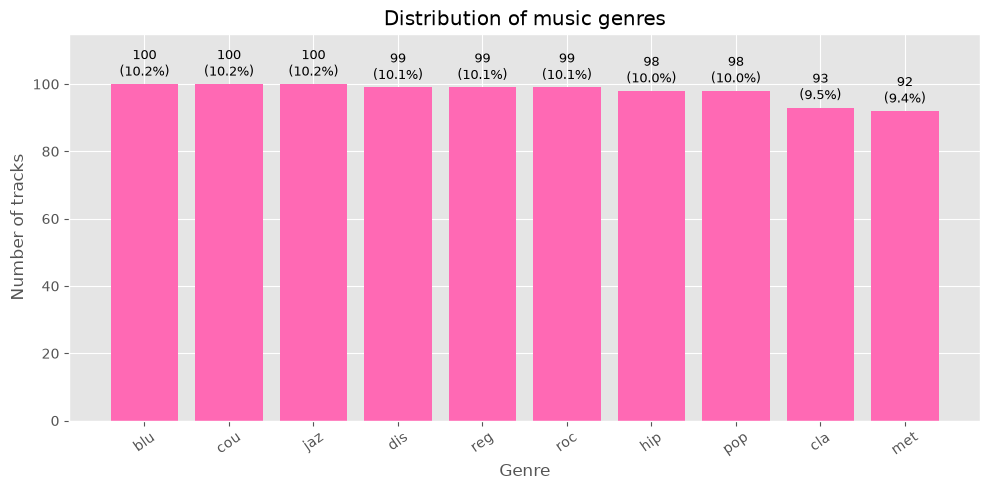

In [17]:
#target column distribution
# genre_df['genre'].value_counts(normalize=True) * 100. If "Pop" makes up 40% of your dataset and "Jazz" is only 2%, 
# standard algorithms will just blindly guess "Pop" to get an artificially high accuracy score. You need to know this before you train anything.
counts = genre_df[target_col_name].value_counts()
total = counts.sum()

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(counts.index, counts.values, color="hotpink")
ax.bar_label(
    bars,
    labels=[f"{count}\n({count / total:.1%})" for count in counts.values],
    padding=3,
    fontsize=9,
)
ax.set(
    title="Distribution of music genres",
    xlabel="Genre",
    ylabel="Number of tracks",
)
ax.tick_params(axis="x", rotation=35)
ax.margins(y=0.15)
fig.tight_layout()
plt.show()

The genres are almost perfectly balanced. Adjusting class weights could be helpful but not crucial.

## 2. Feature Engineering

In [18]:
import sklearn
sklearn.set_config(transform_output="pandas")
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, OrdinalEncoder
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif

In [19]:
genre_df.head(5)

,highlevel_danceability_value,highlevel_equalization_profile_value,highlevel_excitement_value,highlevel_intensity_value,highlevel_speech_music_value,highlevel_voice_instrumental_value,loudness_dynamic_complexity_dvar,loudness_dynamic_complexity_mean,loudness_dynamic_complexity_var,loudness_larm_dvar,loudness_larm_mean,loudness_larm_var,loudness_replay_gain_value,loudness_vicker_dvar,loudness_vicker_mean,loudness_vicker_var,rhythm_beats_loudness_bass_dvar,rhythm_beats_loudness_bass_mean,rhythm_beats_loudness_bass_var,rhythm_beats_loudness_dvar,rhythm_beats_loudness_mean,rhythm_beats_loudness_var,rhythm_onset_rate_value,spectral_barkbands_00_dvar,spectral_barkbands_00_mean,spectral_barkbands_00_var,spectral_barkbands_01_dvar,spectral_barkbands_01_mean,spectral_barkbands_01_var,spectral_barkbands_02_dvar,spectral_barkbands_02_mean,spectral_barkbands_02_var,spectral_barkbands_03_dvar,spectral_barkbands_03_mean,spectral_barkbands_03_var,spectral_barkbands_04_dvar,spectral_barkbands_04_mean,spectral_barkbands_04_var,spectral_barkbands_05_dvar,spectral_barkbands_05_mean,spectral_barkbands_05_var,spectral_barkbands_06_dvar,spectral_barkbands_06_mean,spectral_barkbands_06_var,spectral_barkbands_07_dvar,spectral_barkbands_07_mean,spectral_barkbands_07_var,spectral_barkbands_08_dvar,spectral_barkbands_08_mean,spectral_barkbands_08_var,spectral_barkbands_09_dvar,spectral_barkbands_09_mean,spectral_barkbands_09_var,spectral_barkbands_10_dvar,spectral_barkbands_10_mean,spectral_barkbands_10_var,spectral_barkbands_11_dvar,spectral_barkbands_11_mean,spectral_barkbands_11_var,spectral_barkbands_12_dvar,spectral_barkbands_12_mean,spectral_barkbands_12_var,spectral_barkbands_13_dvar,spectral_barkbands_13_mean,spectral_barkbands_13_var,spectral_barkbands_14_dvar,spectral_barkbands_14_mean,spectral_barkbands_14_var,spectral_barkbands_15_dvar,spectral_barkbands_15_mean,spectral_barkbands_15_var,spectral_barkbands_16_dvar,spectral_barkbands_16_mean,spectral_barkbands_16_var,spectral_barkbands_17_dvar,spectral_barkbands_17_mean,spectral_barkbands_17_var,spectral_barkbands_18_dvar,spectral_barkbands_18_mean,spectral_barkbands_18_var,spectral_barkbands_19_dvar,spectral_barkbands_19_mean,spectral_barkbands_19_var,spectral_barkbands_20_dvar,spectral_barkbands_20_mean,spectral_barkbands_20_var,spectral_barkbands_21_dvar,spectral_barkbands_21_mean,spectral_barkbands_21_var,spectral_barkbands_22_dvar,spectral_barkbands_22_mean,spectral_barkbands_22_var,spectral_barkbands_23_dvar,spectral_barkbands_23_mean,spectral_barkbands_23_var,spectral_barkbands_24_dvar,spectral_barkbands_24_mean,spectral_barkbands_24_var,spectral_barkbands_25_mean,spectral_barkbands_kurtosis_dvar,spectral_barkbands_kurtosis_mean,spectral_barkbands_kurtosis_var,spectral_barkbands_skewness_dvar,spectral_barkbands_skewness_mean,spectral_barkbands_skewness_var,spectral_barkbands_spread_dvar,spectral_barkbands_spread_mean,spectral_barkbands_spread_var,spectral_centroid_dvar,spectral_centroid_mean,spectral_centroid_var,spectral_crest_dvar,spectral_crest_mean,spectral_crest_var,spectral_decrease_dvar,spectral_decrease_mean,spectral_decrease_var,spectral_energy_dvar,spectral_energy_mean,spectral_energy_var,spectral_energybandratio_high_dvar,spectral_energybandratio_high_mean,spectral_energybandratio_high_var,spectral_energybandratio_low_dvar,spectral_energybandratio_low_mean,spectral_energybandratio_low_var,spectral_energybandratio_middle_high_dvar,spectral_energybandratio_middle_high_mean,spectral_energybandratio_middle_high_var,spectral_energybandratio_middle_low_dvar,spectral_energybandratio_middle_low_mean,spectral_energybandratio_middle_low_var,spectral_flatness_db_dvar,spectral_flatness_db_mean,spectral_flatness_db_var,spectral_flux_dvar,spectral_flux_mean,spectral_flux_var,spectral_hfc_dvar,spectral_hfc_mean,spectral_hfc_var,spectral_kurtosis_dvar,spectral_kurtosis_mean,spectral_kurtosis_var,spectral_mfcc_00_dvar,spectral_mfcc_00_mean,spectral_mfcc_00_var,spectral_mfcc_01_dvar,spectral_

To accomodate possible outliers we will use Robust Scaler

In [20]:
# scaling and encoding
cat_columns = cat_columns.drop("genre")
print(cat_columns.shape)

scaler_and_encoder = ColumnTransformer(
    transformers=[
    ('num', RobustScaler(), num_columns),
    ('cat', OrdinalEncoder(), cat_columns)
])

(3,)


In [21]:
# Remove one feature from each pair whose absolute correlation exceeds the threshold.

class CorrelationFilter(BaseEstimator, TransformerMixin):
    def __init__(self, threshold=0.85):
        self.threshold = threshold

    def fit(self, X, y=None):
        # With transform_output="pandas", X is a DataFrame.
        corr_matrix = X.corr().abs()
        
        # Keep the first feature in column order and compare later features
        # against retained features, avoiding unnecessary drops in correlation chains.
        self.to_drop_ = []
        kept_columns = []
        for column in corr_matrix.columns:
            if any(
                corr_matrix.loc[column, kept] > self.threshold
                for kept in kept_columns
            ):
                self.to_drop_.append(column)
            else:
                kept_columns.append(column)

        # Optional supervised alternative: choose the feature in each pair with
        # the stronger association with y. For multiclass y, use a class-aware
        # score rather than correlation with arbitrary encoded class numbers.
        # upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
        # high_corr_pairs = [
        #     (column, row)
        #     for column in upper.columns
        #     for row in upper.index
        #     if upper.loc[row, column] > self.threshold
        # ]
        # target_series = pd.Series(y, index=X.index)
        # self.to_drop_ = []
        # for column, row in high_corr_pairs:
        #     corr_column = X[column].corr(target_series)
        #     corr_row = X[row].corr(target_series)
        #     if abs(corr_column) < abs(corr_row):
        #         self.to_drop_.append(column)
        #     else:
        #         self.to_drop_.append(row)

        return self

    def transform(self, X):
        # Return a DataFrame so downstream steps retain feature names.
        return X.drop(columns=[col for col in self.to_drop_ if col in X.columns])

In [44]:
#LR, kNN, ANN
preprocessor_1 = Pipeline(steps=[
    ('scaler_and_labeler', scaler_and_encoder),
    ('corr_filter', CorrelationFilter(threshold=0.9)),
    ('feature_selection', SelectKBest(score_func=f_classif, k=40))
])

#Trees, XGB
preprocessor_2 = Pipeline(steps=[
    ('scaler_and_labeler', scaler_and_encoder)
])

## 3. Classification

In [23]:
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.base import clone

from sklearn.model_selection import StratifiedKFold, GridSearchCV, train_test_split


### Training and model selection

In [24]:
#encoding the target column into integers
le = LabelEncoder()
y = le.fit_transform(genre_df['genre'])

In [53]:
X = genre_df.drop(columns=["genre"])

# Keep one stratified test split untouched during tuning and model selection.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
cv_tuning = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
model_searches = {}
cv_results = []

class BalancedMLPClassifier(MLPClassifier):
    def fit(self, X, y):
        sample_weight = compute_sample_weight(class_weight="balanced", y=y)
        return super().fit(X, y, sample_weight=sample_weight)


def tune_model(search, model_name):
    search = clone(search).set_params(cv=cv_tuning)
    search.fit(X_train, y_train)
    best_index = search.best_index_
    train_accuracy = search.cv_results_["mean_train_score"][best_index]

    print(f"\n{model_name}")
    print(f"Best parameters: {search.best_params_}")
    print(
        f"10-fold CV accuracy: train={train_accuracy:.3f}, "
        f"validation={search.best_score_:.3f}"
    )
    display(search)

    model_searches[model_name] = search
    cv_results.append({
        "Model": model_name,
        "CV train accuracy": train_accuracy,
        "CV validation accuracy": search.best_score_,
        "Best parameters": search.best_params_,
    })
    return search

### Logistic Regression

In [54]:
lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_1),
    ('classifier', LogisticRegression(class_weight='balanced', solver='saga', max_iter=2000, random_state=42))
])

#for finetuning
param_grid = {
    'preprocessor__feature_selection__k': [100, 120, 140, 'all'], 
    'classifier__C': [0.5, 0.7, 1.0, 1.5], 
    'classifier__l1_ratio': [0.0, 1.0]# 1.0 is L1 (Lasso) handles un-deleted outliers safely, 0.0 is L2 (Ridge)
}

lr_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid,
    cv=10,
    scoring="accuracy",
    refit=True,
    return_train_score=True,
    n_jobs=-1
)

lr_search = tune_model(lr_search, "Logistic Regression")

/Users/lidiawisniewska/Desktop/SMC/ML-for-Sound-and-Music/.ml/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/lidiawisniewska/Desktop/SMC/ML-for-Sound-and-Music/.ml/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/lidiawisniewska/Desktop/SMC/ML-for-Sound-and-Music/.ml/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/lidiawisniewska/Desktop/SMC/ML-for-Sound-and-Music/.ml/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/lidiawisniewska/Desktop/SMC/ML-for-Sound-and-Music/.ml/lib/python3.14/site-packages/sklea


Logistic Regression
Best parameters: {'classifier__C': 0.7, 'classifier__l1_ratio': 1.0, 'preprocessor__feature_selection__k': 120}
10-fold CV accuracy: train=0.967, validation=0.840


/Users/lidiawisniewska/Desktop/SMC/ML-for-Sound-and-Music/.ml/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...ver='saga'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.5, 0.7, ...], 'classifier__l1_ratio': [0.0, 1.0], 'preprocessor__feature_selection__k': [100, 120, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` wi

### kNN

In [55]:
knn_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_1),
("classifier", KNeighborsClassifier()),
])

param_grid = {
    "preprocessor__feature_selection__k": [60, 100, 140, "all"],
    "classifier__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "classifier__weights": ["uniform", "distance"],
    "classifier__metric": ["minkowski"],
    "classifier__p": [1, 2],  # 1 = Manhattan, 2 = Euclidean
}

knn_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    cv=10,
    scoring="accuracy",
    refit=True,
    return_train_score=True,
    n_jobs=-1,
)

knn_search = tune_model(knn_search, "kNN")


kNN
Best parameters: {'classifier__metric': 'minkowski', 'classifier__n_neighbors': 7, 'classifier__p': 1, 'classifier__weights': 'distance', 'preprocessor__feature_selection__k': 100}
10-fold CV accuracy: train=1.000, validation=0.757


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__metric': ['minkowski'], 'classifier__n_neighbors': [3, 5, ...], 'classifier__p': [1, 2], 'classifier__weights': ['uniform', 'distance'], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_sc

### Decision Tree

In [56]:
dt_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_2),
    ("classifier", DecisionTreeClassifier(class_weight="balanced", random_state=42)),
])

dt_param_grid = {
    "classifier__criterion": ["gini", "entropy"],
    "classifier__max_depth": [None, 5, 10, 20],
    "classifier__min_samples_leaf": [1, 2, 5],
    "classifier__ccp_alpha": [0.0, 0.01, 0.05],
}

dt_search = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=dt_param_grid,
    cv=10,
    scoring="accuracy",
    refit=True,
    return_train_score=True,
    n_jobs=-1,
)

dt_search = tune_model(dt_search, "Decision Tree")


Decision Tree
Best parameters: {'classifier__ccp_alpha': 0.0, 'classifier__criterion': 'entropy', 'classifier__max_depth': None, 'classifier__min_samples_leaf': 1}
10-fold CV accuracy: train=1.000, validation=0.643


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__ccp_alpha': [0.0, 0.01, ...], 'classifier__criterion': ['gini', 'entropy'], 'classifier__max_depth': [None, 5, ...], 'classifier__min_samples_leaf': [1, 2, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``bes

### Random Forest

In [65]:
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_2),
    ("classifier", RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=1,  # GridSearchCV handles parallelism
    )),
])

rf_param_grid = {
    "classifier__n_estimators": [100, 300],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_leaf": [1, 2],
    "classifier__max_features": ["sqrt", 0.5],
    "classifier__ccp_alpha": [0.0, 0.01, 0.05]
}

rf_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    cv=10,
    scoring="accuracy",
    refit=True,
    return_train_score=True,
    n_jobs=-1,
)

rf_search = tune_model(rf_search, "Random Forest")


Random Forest
Best parameters: {'classifier__ccp_alpha': 0.0, 'classifier__max_depth': None, 'classifier__max_features': 0.5, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 100}
10-fold CV accuracy: train=1.000, validation=0.795


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__ccp_alpha': [0.0, 0.01, ...], 'classifier__max_depth': [None, 10, ...], 'classifier__max_features': ['sqrt', 0.5], 'classifier__min_samples_leaf': [1, 2], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_

### ANN (MLP)

In [68]:
mlp_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_1),
    ("classifier", BalancedMLPClassifier(
        solver="adam",
        max_iter=500,
        early_stopping=True,
        random_state=42,
    )),
])

mlp_param_grid = {
    "preprocessor__feature_selection__k": [60, 100, 140, "all"],
    "classifier__hidden_layer_sizes": [(64,), (128,), (64, 32), (128, 64)],
    "classifier__alpha": [0.001, 0.01],
    "classifier__learning_rate_init": [0.01, 0.05, 0.1],
}

mlp_search = GridSearchCV(
    estimator=mlp_pipeline,
    param_grid=mlp_param_grid,
    cv=10,
    scoring="accuracy",
    refit=True,
    return_train_score=True,
    n_jobs=-1,
)

mlp_search = tune_model(mlp_search, "MLP")

print("MLP best CV parameters:", mlp_search.best_params_)



MLP
Best parameters: {'classifier__alpha': 0.001, 'classifier__hidden_layer_sizes': (128, 64), 'classifier__learning_rate_init': 0.01, 'preprocessor__feature_selection__k': 140}
10-fold CV accuracy: train=0.984, validation=0.817


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__alpha': [0.001, 0.01], 'classifier__hidden_layer_sizes': [(64,), (128,), ...], 'classifier__learning_rate_init': [0.01, 0.05, ...], 'preprocessor__feature_selection__k': [60, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluati

MLP best CV parameters: {'classifier__alpha': 0.001, 'classifier__hidden_layer_sizes': (128, 64), 'classifier__learning_rate_init': 0.01, 'preprocessor__feature_selection__k': 140}


### Class weighting

The genre counts are slightly imbalanced. Logistic Regression, Decision Trees, and Random Forests use class_weight='balanced'; the MLP uses balanced sample weights. Standard kNN has no class-weight support, so it is used without oversampling. The Decision Tree and Random Forest grids also tune cost-complexity pruning with ccp_alpha. The kNN grid explores neighbor counts up to 51, along with feature count, distance weighting, and Manhattan or Euclidean distance.

Accuracy is used as the model-selection and evaluation metric.

Outliers ---
Musisz tylko pamiętać, aby przy konfiguracji Regresji Logistycznej lub Sieci Neuronowej (ANN) użyć regularyzacji L1 (Lasso) lub absolutnej funkcji błędu (MAE), aby gradient nie oszalał na tych pozostawionych anomaliach

Early stopping

In [71]:
#drop mlp
cv_results.pop(-3)
cv_results

[{'Model': 'Logistic Regression',
  'CV train accuracy': np.float64(0.9674631045519202),
  'CV validation accuracy': np.float64(0.8402304446608244),
  'Best parameters': {'classifier__C': 0.7,
   'classifier__l1_ratio': 1.0,
   'preprocessor__feature_selection__k': 120},
  'Test accuracy': 0.8724489795918368},
 {'Model': 'kNN',
  'CV train accuracy': np.float64(1.0),
  'CV validation accuracy': np.float64(0.7570593962999026),
  'Best parameters': {'classifier__metric': 'minkowski',
   'classifier__n_neighbors': 7,
   'classifier__p': 1,
   'classifier__weights': 'distance',
   'preprocessor__feature_selection__k': 100},
  'Test accuracy': 0.7653061224489796},
 {'Model': 'Decision Tree',
  'CV train accuracy': np.float64(1.0),
  'CV validation accuracy': np.float64(0.6433950016228497),
  'Best parameters': {'classifier__ccp_alpha': 0.0,
   'classifier__criterion': 'entropy',
   'classifier__max_depth': None,
   'classifier__min_samples_leaf': 1},
  'Test accuracy': 0.6530612244897959},


## 4. Evaluation

All candidate models are tuned using the same 10-fold stratified cross-validation on the training portion of one stratified split (seed 42). GridSearchCV refits each model's best configuration on the full training split. Each fitted model is then evaluated on the same held-out test split, and its predictions are retained for error analysis.

Use CV validation accuracy to select the model, not test accuracy. The test scores are for comparison and analysis on this split; analyses based on the test set are exploratory. Each fitted search in `model_searches` is trained only on the training split, so it can also be inspected for selected features. Previously saved outputs are stale; rerun the model and evaluation cells to generate current results.

In [72]:
test_predictions = {}
for result in cv_results:
    model_name = result["Model"]
    search = model_searches[model_name]
    result["Test accuracy"] = search.score(X_test, y_test)
    test_predictions[model_name] = search.predict(X_test)

cv_summary = pd.DataFrame(cv_results).sort_values(
    "CV validation accuracy", ascending=False
).reset_index(drop=True)
display(cv_summary.drop(columns="Best parameters").round(3))
display(cv_summary[["Model", "Best parameters"]])

best_model_name = max(
    model_searches,
    key=lambda name: model_searches[name].best_score_,
)
best_search = model_searches[best_model_name]
print(f"Selected model by 10-fold CV accuracy: {best_model_name}")
print(f"Selected model parameters: {best_search.best_params_}")
print(f"Mean 10-fold CV validation accuracy: {best_search.best_score_:.3f}")
print(f"Selected model held-out test accuracy: {best_search.score(X_test, y_test):.3f}")

,Model,CV train accuracy,CV validation accuracy,Test accuracy
0,Logistic Regression,0.967,0.840,0.872
1,MLP,0.984,0.817,0.837
2,Random Forest,1.000,0.795,0.842
3,kNN,1.000,0.757,0.765
4,Decision Tree,1.000,0.643,0.653


,Model,Best parameters
0,Logistic Regression,"{'classifier__C': 0.7, 'classifier__l1_ratio':..."
1,MLP,"{'classifier__alpha': 0.001, 'classifier__hidd..."
2,Random Forest,"{'classifier__ccp_alpha': 0.0, 'classifier__ma..."
3,kNN,"{'classifier__metric': 'minkowski', 'classifie..."
4,Decision Tree,"{'classifier__ccp_alpha': 0.0, 'classifier__cr..."


Selected model by 10-fold CV accuracy: Logistic Regression
Selected model parameters: {'classifier__C': 0.7, 'classifier__l1_ratio': 1.0, 'preprocessor__feature_selection__k': 120}
Mean 10-fold CV validation accuracy: 0.840
Selected model held-out test accuracy: 0.872


### Saving fitted models

In [73]:
from pathlib import Path
import joblib
import sklearn

models_dir = Path("models")
if not models_dir.exists() and Path("lab1").is_dir():
    models_dir = Path("lab1") / models_dir
models_dir.mkdir(parents=True, exist_ok=True)

model_artifact = {
    "models": {
        name: search.best_estimator_
        for name, search in model_searches.items()
    },
    "label_encoder": le,
    "feature_columns": list(X.columns),
    "best_parameters": {
        name: search.best_params_
        for name, search in model_searches.items()
    },
    "sklearn_version": sklearn.__version__,
}
model_path = models_dir / "genre_classifiers.joblib"
joblib.dump(model_artifact, model_path)
print(f"Saved {len(model_artifact['models'])} fitted models to {model_path}")

Saved 5 fitted models to models/genre_classifiers.joblib
